In [32]:

import pandas as pd
import loguru as logging
from PIL import Image
import numpy as np

### Initial loading and merging of datasets

In [33]:
mapping = pd.read_csv(r"D:\galaxy classification\data\raw\mapping.csv")
labels = pd.read_csv(r"D:\galaxy classification\data\raw\labels.csv")

In [34]:
merge = pd.merge(mapping, labels, left_on='objid', right_on='dr7objid')
merge.head()

,objid,sample_x,asset_id,dr7objid,ra,dec,rastring,decstring,sample_y,gz2_class,...,t11_arms_number_a36_more_than_4_fraction,t11_arms_number_a36_more_than_4_weighted_fraction,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a36_more_than_4_flag,t11_arms_number_a37_cant_tell_count,t11_arms_number_a37_cant_tell_weight,t11_arms_number_a37_cant_tell_fraction,t11_arms_number_a37_cant_tell_weighted_fraction,t11_arms_number_a37_cant_tell_debiased,t11_arms_number_a37_cant_tell_flag
0,587722981741363294,original,3,587722981741363294,182.925262,-1.092357,12:11:42.06,-01:05:32.5,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
1,587722981741363323,original,4,587722981741363323,182.970108,-1.219537,12:11:52.83,-01:13:10.3,original,Sc?l,...,0.0,0.0,0.0,0,1,1.0,1.0,1.0,1.0,1
2,587722981741559888,original,5,587722981741559888,183.438095,-1.238414,12:13:45.14,-01:14:18.3,original,Er,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
3,587722981741625481,original,6,587722981741625481,183.473999,-1.231429,12:13:53.76,-01:13:53.1,original,Sc1t,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
4,587722981741625484,original,7,587722981741625484,183.477783,-1.084604,12:13:54.67,-01:05:04.6,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0


In [35]:
merge["gz2_class"].value_counts()

gz2_class
Ei          44038
Er          36764
Ser         14009
Sc?t        13509
Ec          10149
            ...  
Sd1t(o)         1
SBc4m(m)        1
SBd?t(r)        1
SBc1t(u)        1
SBd+m(i)        1
Name: count, Length: 818, dtype: int64

### Filtering diebiased data and also making viewable function


In [36]:
dir = r"D:\galaxy classification\images"

def load_image(id):
    img_path = f"{dir}/{id}.jpg"
    img = Image.open(img_path).convert('RGB')
    return img


In [37]:
debiased_df = merge[["objid","asset_id","sample_x","total_votes"]+[col for col in merge.columns if col.endswith('_debiased')]]
debiased_df

,objid,asset_id,sample_x,total_votes,t01_smooth_or_features_a01_smooth_debiased,t01_smooth_or_features_a02_features_or_disk_debiased,t01_smooth_or_features_a03_star_or_artifact_debiased,t02_edgeon_a04_yes_debiased,t02_edgeon_a05_no_debiased,t03_bar_a06_bar_debiased,...,t09_bulge_shape_a27_no_bulge_debiased,t10_arms_winding_a28_tight_debiased,t10_arms_winding_a29_medium_debiased,t10_arms_winding_a30_loose_debiased,t11_arms_number_a31_1_debiased,t11_arms_number_a32_2_debiased,t11_arms_number_a33_3_debiased,t11_arms_number_a34_4_debiased,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a37_cant_tell_debiased
0,587722981741363294,3,original,181,0.459,0.681,0.000,0.041914,0.914402,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
1,587722981741363323,4,original,111,0.216,0.736,0.000,0.000000,1.000000,0.376434,...,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
2,587722981741559888,5,original,153,0.773,0.029,0.114,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
3,587722981741625481,6,original,136,0.152,0.639,0.009,0.000000,1.000000,0.000000,...,0.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000
4,587722981741625484,7,original,150,0.182,0.720,0.032,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239690,588015510368681992,295294,stripe82,273,0.000,1.000,0.000,0.000000,1.000000,0.912724,...,0.00000,0.395750,0.516223,0.080662,0.000000,0.068418,0.058680,0.50517,0.419035,0.029496
239691,588015510368682105,295295,stripe82,149,0.800,0.146,0.073,0.126668,0.836558,0.000000,...,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
239692,588015510368682132,295296,stripe82,138,0.733,0.190,0.022,0.861468,0.232142,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
239693,588015510636265643,295304,stripe82,213,0.089,0.892,0.010,0.343208,0.668841,0.228637,...,0.58578,0.313458,0.266263,0.361677,0.075168,0.115436,0.000000,0.00000,0.000000,0.692101


In [38]:
debiased_df.columns[debiased_df.columns.str.contains("t07")].value_counts()

t07_rounded_a16_completely_round_debiased    1
t07_rounded_a17_in_between_debiased          1
t07_rounded_a18_cigar_shaped_debiased        1
Name: count, dtype: int64

## Method 1 
Using thresholds for galaxy classification based on voting by [Zhu et al., 2019](https://arxiv.org/abs/1807.10406)

| Class | CleanSample | Tasks | T01 | T01_Label | T01_Val | T07 | T07_Label | T07_Val |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | Completelyroundsmooth | T01 | 8434 | fsmooth | 0.469 | 1 | fcompletely round | 0.50 |
| 1 | In-betweensmooth | T01 | 8069 | fsmooth | 0.469 | 2 | fbetween | 0.50 |
| 2 | Cigar-shaped smooth | T01 | 578 | fsmooth | 0.469 | 3 | fcigar shaped | 0.50 |
| 3 | Edge-on | T01 | 3903 | ffeaturesdisk | 0.430 | T02 | fedge onyes | 0.602 |
| 4 | Spiral | T02 | 7806 | fedge onno | 0.715 |  |  |  |

In [39]:
df_debiased = debiased_df[debiased_df["total_votes"] > 50] #reccomended by the paper

<Axes: >

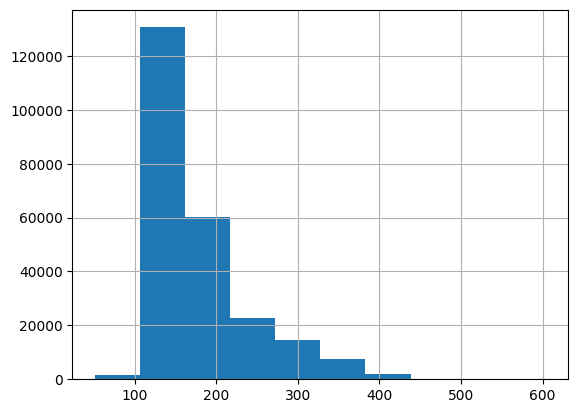

In [40]:
df_debiased["total_votes"].hist(bins=10)

In [ ]:
f_smooth = 0.469
f_completely_round = 0.500
f_in_between = 0.500      #initializing thresholds
f_cigar_shaped = 0.500
f_faturesdisk = 0.430
f_edge_onyes = 0.602
f_edge_onno = 0.715
f_spiral_yes = 0.619

### Filtering for smooth and completely round galaxies

In [ ]:
f_smooth_mask = debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('smooth_debiased') #selecting right columns mask
f_completely_round_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('completely_round_debiased')

smooth_cols = debiased_df.columns[f_smooth_mask].tolist() #selecting the column with the mask
completely_round_cols = debiased_df.columns[f_completely_round_mask].tolist()

print('Smooth columns:', smooth_cols)
print('Completely round columns:', completely_round_cols)

Smooth columns: ['t01_smooth_or_features_a01_smooth_debiased']
Completely round columns: ['t07_rounded_a16_completely_round_debiased']


array([[<Axes: title={'center': 't07_rounded_a16_completely_round_debiased'}>,
        <Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>]],
      dtype=object)

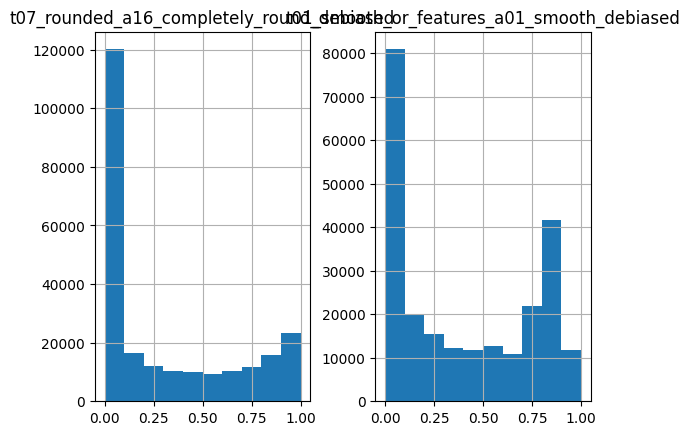

In [43]:
debiased_df[completely_round_cols+smooth_cols].hist()

In [ ]:
mask = (df_debiased[smooth_cols] >= f_smooth).any(axis=1) & (df_debiased[completely_round_cols] >= f_completely_round).any(axis=1) #mask to filter the data
smooth_completely_round_df = df_debiased[mask].dropna()#filtering the data

array([[<Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>,
        <Axes: title={'center': 't07_rounded_a16_completely_round_debiased'}>]],
      dtype=object)

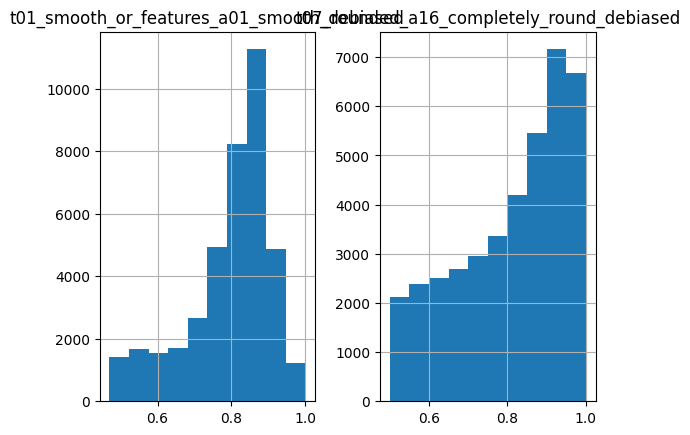

In [45]:
smooth_completely_round_df[smooth_cols + completely_round_cols].hist()

### Filtering In-between smooth galaxies

In [46]:
f_in_between_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('in_between_debiased')

in_between_cols = debiased_df.columns[f_in_between_mask].tolist()

print('In-between columns:', in_between_cols)

In-between columns: ['t07_rounded_a17_in_between_debiased']


In [ ]:
mask1 = (df_debiased[smooth_cols] >= f_smooth).any(axis=1) & (df_debiased[in_between_cols] >= f_in_between).any(axis=1)
in_between_smooth_df = df_debiased[mask1].dropna()

array([[<Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>,
        <Axes: title={'center': 't07_rounded_a17_in_between_debiased'}>]],
      dtype=object)

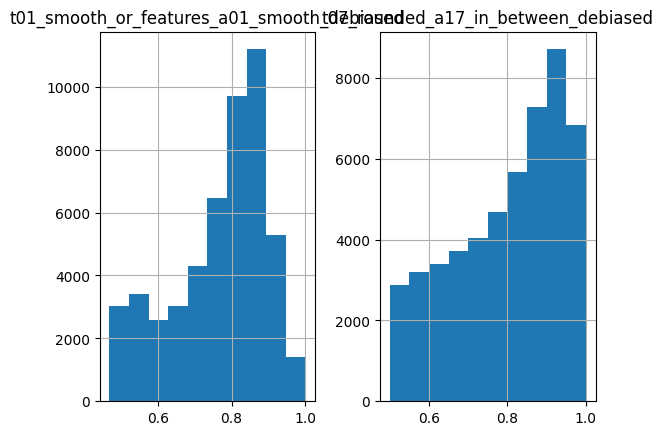

In [48]:
in_between_smooth_df[smooth_cols + in_between_cols].hist()

In [ ]:
common_inbetwee_and_completly_smooth = pd.merge(in_between_smooth_df, smooth_completely_round_df, on='objid', how='inner') #join to find common

#### Cigar Shaped Smooth

In [72]:
cigar_shaped_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('cigar_shaped_debiased')
cigar_shaped_cols = debiased_df.columns[cigar_shaped_mask].tolist()
mask2 = (df_debiased[cigar_shaped_cols] >= f_cigar_shaped).any(axis=1) & (df_debiased[smooth_cols] >= f_smooth).any(axis=1)
cigar_shaped_df = df_debiased[mask2].dropna()

In [73]:
cigar_shaped_df.shape

(15474, 41)

#### Edge-on

In [75]:
edge_on_yes_mask = debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('yes_debiased')
edge_on_yes_cols = debiased_df.columns[edge_on_yes_mask].tolist()

feature_disk_mask = debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('features_or_disk_debiased')
feature_disk_cols = debiased_df.columns[feature_disk_mask].tolist()

mask3 = (df_debiased[edge_on_yes_cols] >= f_edge_onyes).any(axis=1) & (df_debiased[feature_disk_cols] >= f_faturesdisk).any(axis=1)
edge_on_yes_df = df_debiased[mask3].dropna()




In [78]:
edge_on_yes_df

,objid,asset_id,sample_x,total_votes,t01_smooth_or_features_a01_smooth_debiased,t01_smooth_or_features_a02_features_or_disk_debiased,t01_smooth_or_features_a03_star_or_artifact_debiased,t02_edgeon_a04_yes_debiased,t02_edgeon_a05_no_debiased,t03_bar_a06_bar_debiased,...,t09_bulge_shape_a27_no_bulge_debiased,t10_arms_winding_a28_tight_debiased,t10_arms_winding_a29_medium_debiased,t10_arms_winding_a30_loose_debiased,t11_arms_number_a31_1_debiased,t11_arms_number_a32_2_debiased,t11_arms_number_a33_3_debiased,t11_arms_number_a34_4_debiased,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a37_cant_tell_debiased
20,587722981743067266,24,original,141,0.143,0.875,0.001,0.884189,0.355738,1.000000,...,0.398099,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000
45,587722981745295552,49,original,200,0.240,0.760,0.000,0.947000,0.053000,0.000000,...,0.861000,1.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,1.00000
55,587722981745623268,59,original,180,0.045,0.940,0.023,0.734627,0.515795,0.000000,...,0.624942,1.0,0.000000,0.000000,0.0,1.000000,0.0,0.0,0.0,0.00000
57,587722981745754253,61,original,162,0.000,1.000,0.000,1.000000,0.000000,0.000000,...,0.527035,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000
61,587722981746540704,68,original,134,0.005,0.976,0.000,0.824479,0.393211,0.000000,...,0.410747,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239661,588015510366585045,295245,stripe82,147,0.295,0.648,0.073,1.000000,0.000000,0.000000,...,0.536557,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000
239669,588015510367240328,295259,stripe82,188,0.077,0.944,0.010,1.000000,0.000000,0.000000,...,0.048416,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000
239670,588015510367436938,295261,stripe82,224,0.151,0.842,0.004,0.761780,0.300169,0.303686,...,0.600253,0.0,0.651669,0.300845,0.0,0.286015,0.0,0.0,0.0,0.65042
239678,588015510367961246,295275,stripe82,151,0.263,0.807,0.000,0.957057,0.075803,1.000000,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.00000


#### sprial

In [80]:
edge_on_no_mask = debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('no_debiased')
edge_on_no_cols = debiased_df.columns[edge_on_no_mask].tolist()

spiral_yes_mask = debiased_df.columns.str.startswith('t04') & debiased_df.columns.str.endswith('spiral_debiased')
spiral_yes_cols = debiased_df.columns[spiral_yes_mask].tolist()

mask4 = (df_debiased[edge_on_no_cols] >= f_edge_onno).any(axis=1) & (df_debiased[spiral_yes_cols] >= f_spiral_yes).any(axis=1) \
        & (df_debiased[feature_disk_cols] >= f_faturesdisk).any(axis=1)

spiral_yes_df = df_debiased[mask4].dropna()

In [ ]:
# Compute intersection of 'objid' across the category DataFrames without merging all columns
dfs = [smooth_completely_round_df, in_between_smooth_df, cigar_shaped_df, edge_on_yes_df, spiral_yes_df]
# Start from the first df's objid set and intersect with the others
common_ids = set(dfs[0]['objid']) if len(dfs) > 0 else set()
for d in dfs[1:]:
    common_ids &= set(d['objid'])
# Create a small DataFrame of the common ids
common = pd.DataFrame({'objid': sorted(common_ids)})
print('Common objects (unique objid):', len(common_ids))
# Optional: join back to df_debiased to get full rows for those objids
common = pd.merge(df_debiased, common, on='objid', how='inner')

MergeError: Passing 'suffixes' which cause duplicate columns {'t03_bar_a07_no_bar_debiased_x', 't03_bar_a06_bar_debiased_x', 'sample_x_x', 't07_rounded_a17_in_between_debiased_x', 't01_smooth_or_features_a02_features_or_disk_debiased_x', 't07_rounded_a18_cigar_shaped_debiased_x', 't07_rounded_a16_completely_round_debiased_x', 'asset_id_x', 't11_arms_number_a32_2_debiased_x', 'total_votes_x', 't11_arms_number_a31_1_debiased_x', 't06_odd_a14_yes_debiased_x', 't08_odd_feature_a21_disturbed_debiased_x', 't08_odd_feature_a38_dust_lane_debiased_x', 't08_odd_feature_a19_ring_debiased_x', 't05_bulge_prominence_a11_just_noticeable_debiased_x', 't05_bulge_prominence_a10_no_bulge_debiased_x', 't08_odd_feature_a23_other_debiased_x', 't10_arms_winding_a30_loose_debiased_x', 't09_bulge_shape_a25_rounded_debiased_x', 't11_arms_number_a37_cant_tell_debiased_x', 't08_odd_feature_a24_merger_debiased_x', 't02_edgeon_a04_yes_debiased_x', 't11_arms_number_a33_3_debiased_x', 't10_arms_winding_a28_tight_debi